In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

# The GMM is fit in a power transformed space, so the helpers that convert
# the components back into a density over microns live in the export script.
import export_trajectories as et

In [2]:
# Helper method for saving the plots. 
def saveplot(filename, dpi=300, fig=None): 
    if fig is None: 
        fig = plt.gcf()
    # Save the figure as a png file. 
    fig.savefig(filename, dpi=dpi)
    # Also save the figure as a pdf. 
    fig.savefig(filename.replace('.png', '.pdf'), dpi=dpi)

# Load the data. 
It is all stored in a single csv file with the GMM components stored in a separate csv file. 

In [3]:
traj_data = pd.read_csv('./trajectories/all_trajectories.csv')
traj_data

,Mutant,CEN,Cell ID,Time (sec),Spindle Length (um),Centromere Separation (um),Tension Classification,Time Until Anaphase (sec)
0,WT,CENIV,2024_07_09_Stack10_Subset2,0,1.458729,0.145182,No Tension,NaN
1,WT,CENIV,2024_07_09_Stack10_Subset2,20,1.361910,0.649674,Low Tension,NaN
2,WT,CENIV,2024_07_09_Stack10_Subset2,40,1.186622,0.150275,No Tension,NaN
3,WT,CENIV,2024_07_09_Stack10_Subset2,60,0.987667,0.505190,Low Tension,NaN
4,WT,CENIV,2024_07_09_Stack10_Subset2,80,1.059648,0.339280,Low Tension,NaN
...,...,...,...,...,...,...,...,...
36733,Ase1-7A,CENXV,2026_05_28_Stack4_SIM²_Cell35,2460,1.492971,0.501934,Low Tension,NaN
36734,Ase1-7A,CENXV,2026_05_28_Stack4_SIM²_Cell35,2480,1.268460,0.015684,No Tension,NaN
36735,Ase1-7A,CENXV,2026_05_28_Stack4_SIM²_Cell35,2500,1.033775,0.242703,Low Tension,NaN
36736,Ase1-7A,CENXV,2026_05_28_Stack4_SIM²_Cell35,2520,1.160765,0.186700,Low Tension,NaN


In [4]:
gmm_data = pd.read_csv('./trajectories/gmm_components.csv')
gmm_data

,Strain,YV Strains,Component,Tension State,Mean (transformed),Variance (transformed),Weight,Separation (um),Separation Low (um),Separation High (um),Lambda
0,WT CENIV,"YV3640, YV3670, YV3701, YV3702",0,No Tension,0.081927,0.002924,0.149106,0.089976,0.028725,0.159769,-1.178136
1,WT CENIV,"YV3640, YV3670, YV3701, YV3702",1,Low Tension,0.339984,0.005143,0.548426,0.543980,0.380492,0.756493,-1.178136
2,WT CENIV,"YV3640, YV3670, YV3701, YV3702",2,High Tension,0.410656,0.023319,0.302468,0.752936,0.360005,1.521929,-1.178136
3,Cin8-RK kip1∆ CENIV,"YV3663, YV3673, YV3682, YV3700",0,No Tension,0.072398,0.002043,0.250503,0.079844,0.028177,0.138719,-1.557911
4,Cin8-RK kip1∆ CENIV,"YV3663, YV3673, YV3682, YV3700",1,Low Tension,0.267067,0.004815,0.444949,0.412433,0.266533,0.610801,-1.557911
5,Cin8-RK kip1∆ CENIV,"YV3663, YV3673, YV3682, YV3700",2,High Tension,0.410909,0.010594,0.304548,0.927201,0.521210,1.814340,-1.557911
6,Ase1-7A CENIV,"YV3744, YV3748, YV3841, YV3844",0,No Tension,0.071178,0.001868,0.211039,0.078629,0.029038,0.135075,-1.641330
7,Ase1-7A CENIV,"YV3744, YV3748, YV3841, YV3844",1,Low Tension,0.269793,0.004818,0.489880,0.428089,0.275053,0.641661,-1.641330
8,Ase1-7A CENIV,"YV3744, YV3748, YV3841, YV3844",2,High Tension,0.362831,0.013482,0.299081,0.735826,0.372004,1.559058,-1.641330
9,WT CENXV,"YV4228, YV4232",0,No Tension,0.091948,0.003431,0.152137,0.102076,0.034616,0.179774,-1.152706


# Plot the Centromere Separation Distributions
This is just the distribution of the centromere separation for every cell of every timepoint. Over this distribution, I plotted the GMM which was fitted on the CENIV data. 

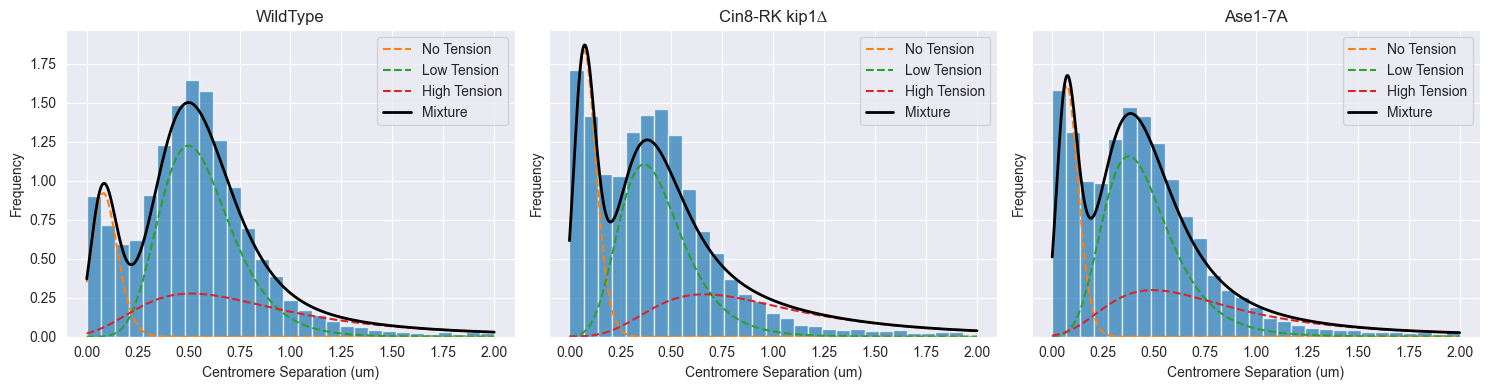

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

def plot_histogram(ax, data, dist_data, n_cells=None):
    # Plot the histogram of the centromere separations. 
    ax.hist(data, bins=np.linspace(0, 2, 30), alpha=0.7, density=True)
    ax.set_xlabel('Centromere Separation (um)')
    ax.set_ylabel('Frequency')

    # Sort by component so the rows line up with the tension state labels.
    dist_data = dist_data.sort_values('Component')
    lam = dist_data['Lambda'].iloc[0]
    means = dist_data['Mean (transformed)'].values
    variances = dist_data['Variance (transformed)'].values
    weights = dist_data['Weight'].values
    states = dist_data['Tension State'].values

    # The components are Gaussian in the transformed space, so they have to
    # be converted back into a density over separation before plotting.
    x = np.linspace(0, 2, 1000)
    for state, mean, variance, weight in zip(states, means, variances, weights):
        density = et.component_density_in_microns(x, mean, variance, weight, lam)
        ax.plot(x, density, '--', label=state)

    mixture = et.mixture_density_in_microns(x, means, variances, weights, lam)
    ax.plot(x, mixture, 'k-', linewidth=2, label='Mixture')
    ax.legend()
    
    if n_cells is not None: 
        ax.text(0.05, 0.95, f'n cells = {n_cells}', transform=ax.transAxes, ha='left', va='top', fontsize=10, color='black', bbox=dict(facecolor='none', alpha=0.5, edgecolor='none'))
    
plot_histogram(axs[0], traj_data[traj_data['Mutant'] == 'WT']['Centromere Separation (um)'], gmm_data[gmm_data['Strain'] == 'WT CENIV'])
axs[0].set_title('WildType')

plot_histogram(axs[1], traj_data[traj_data['Mutant'] == 'Cin8-RK kip1∆']['Centromere Separation (um)'], gmm_data[gmm_data['Strain'] == 'Cin8-RK kip1∆ CENIV'])
axs[1].set_title('Cin8-RK kip1∆')

plot_histogram(axs[2], traj_data[traj_data['Mutant'] == 'Ase1-7A']['Centromere Separation (um)'], gmm_data[gmm_data['Strain'] == 'Ase1-7A CENIV'])
axs[2].set_title('Ase1-7A')

plt.tight_layout()
saveplot('./figs/centromere_separation_distributions.png', dpi=300)

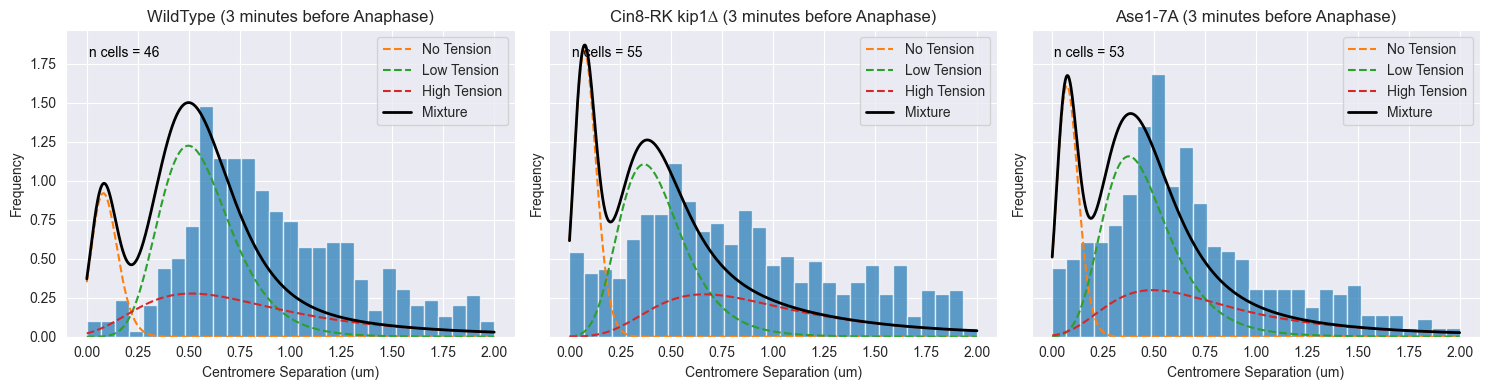

In [6]:
# Limit the dataset to only timepoints within the last 3 mins of metaphase. 
end_metaphase_data = traj_data[(traj_data['Time Until Anaphase (sec)'] >= -180) & (traj_data['Time Until Anaphase (sec)'] <= 0)].copy()
end_metaphase_data.dropna(subset=['Time Until Anaphase (sec)'], inplace=True)

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

plot_histogram(axs[0], end_metaphase_data[end_metaphase_data['Mutant'] == 'WT']['Centromere Separation (um)'], gmm_data[gmm_data['Strain'] == 'WT CENIV'], n_cells=len(end_metaphase_data[end_metaphase_data['Mutant'] == 'WT']['Cell ID'].unique()))
axs[0].set_title('WildType (3 minutes before Anaphase)')

plot_histogram(axs[1], end_metaphase_data[end_metaphase_data['Mutant'] == 'Cin8-RK kip1∆']['Centromere Separation (um)'], gmm_data[gmm_data['Strain'] == 'Cin8-RK kip1∆ CENIV'], n_cells=len(end_metaphase_data[end_metaphase_data['Mutant'] == 'Cin8-RK kip1∆']['Cell ID'].unique()))
axs[1].set_title('Cin8-RK kip1∆ (3 minutes before Anaphase)')

plot_histogram(axs[2], end_metaphase_data[end_metaphase_data['Mutant'] == 'Ase1-7A']['Centromere Separation (um)'], gmm_data[gmm_data['Strain'] == 'Ase1-7A CENIV'], n_cells=len(end_metaphase_data[end_metaphase_data['Mutant'] == 'Ase1-7A']['Cell ID'].unique()))
axs[2].set_title('Ase1-7A (3 minutes before Anaphase)')

plt.tight_layout()
saveplot('./figs/centromere_separation_distributions_end_metaphase.png', dpi=300)

In [7]:
from scipy.stats import mannwhitneyu, shapiro

strains = ['WT', 'Cin8-RK kip1∆', 'Ase1-7A']
for s in strains: 
    print(shapiro(end_metaphase_data[end_metaphase_data['Mutant'] == s]['Centromere Separation (um)']))

p_values = np.zeros((3, 3)) * np.nan
for i, strain1 in enumerate(strains):
    for j, strain2 in enumerate(strains):
        if i < j: 
            data1 = end_metaphase_data[end_metaphase_data['Mutant'] == strain1]['Centromere Separation (um)']
            data2 = end_metaphase_data[end_metaphase_data['Mutant'] == strain2]['Centromere Separation (um)']
            _, p_value = mannwhitneyu(data1, data2)
            p_values[i, j] = p_value

pres = pd.DataFrame(p_values, index=strains, columns=strains)
pres

ShapiroResult(statistic=np.float64(0.8851995140704394), pvalue=np.float64(5.166425953817272e-18))
ShapiroResult(statistic=np.float64(0.9516959677401793), pvalue=np.float64(1.9862778538919913e-12))
ShapiroResult(statistic=np.float64(0.9065643454278733), pvalue=np.float64(1.0882253785558605e-17))


,WT,Cin8-RK kip1∆,Ase1-7A
WT,NaN,0.000028,3.160493e-22
Cin8-RK kip1∆,NaN,NaN,1.996283e-06
Ase1-7A,NaN,NaN,NaN


Analyze the BIC and AIC fop each strain to determine the optimal number of components for the GMM.

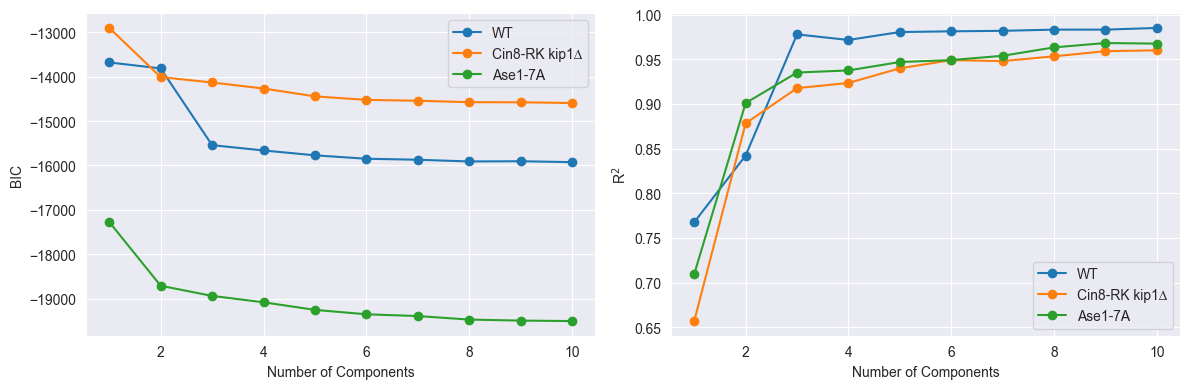

In [8]:
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import PowerTransformer

# Number of histogram bins used for the R^2. Held fixed so the values can be
# compared between strains and between component counts.
R_SQUARED_BINS = 50

def fit_gmm(data, n_components): 
    """Fit a GMM to the data, using the same settings as the export script."""
    observations = np.asarray(data, dtype=float).reshape(-1, 1)
    gmm = GaussianMixture(n_components=n_components, covariance_type='diag',
                          random_state=0, n_init=5)
    gmm.fit(observations)
    return gmm

def compute_bic_aic(data, n_components): 
    """Compute the BIC and AIC for a GMM with a given number of components.

    Both are built from the fitted log likelihood and the number of free
    parameters, and for both of them lower is better."""
    observations = np.asarray(data, dtype=float).reshape(-1, 1)
    gmm = fit_gmm(observations, n_components)
    return gmm.bic(observations), gmm.aic(observations)

def compute_r_squared(data, n_components, bins=R_SQUARED_BINS): 
    """Compute the R^2 for a GMM with a given number of components.

    R^2 measures predicted values against observed ones, so it needs pairs of
    them. A fitted density has no observed counterpart by itself, so the data is
    binned first: the observed values are the heights of a density normalised
    histogram, and the predicted values are the mixture density evaluated at the
    centre of each bin.

        R^2 = 1 - SS_res / SS_tot
        SS_res = sum over bins of (observed - predicted)^2
        SS_tot = sum over bins of (observed - mean observed)^2

    The result is the fraction of the variation in histogram height that the
    mixture accounts for. It depends on the number of bins, so `bins` has to be
    held fixed for any comparison between fits.

    The GMM is fit to `data` as given and the histogram is built from that same
    array, so pass the data in whichever space the mixture is meant to live in."""
    observations = np.asarray(data, dtype=float).reshape(-1, 1)
    gmm = fit_gmm(observations, n_components)

    # Observed: histogram heights as a density, so they are on the same scale as
    # the model rather than being raw counts.
    observed, edges = np.histogram(observations.ravel(), bins=bins, density=True)
    centres = 0.5 * (edges[:-1] + edges[1:])

    # Predicted: score_samples returns the log of the density, so undo the log.
    predicted = np.exp(gmm.score_samples(centres.reshape(-1, 1)))

    residual_sum_of_squares = np.sum((observed - predicted) ** 2)
    total_sum_of_squares = np.sum((observed - np.mean(observed)) ** 2)

    return 1.0 - residual_sum_of_squares / total_sum_of_squares

max_components = 10
component_counts = range(1, max_components + 1)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

for strain in ['WT', 'Cin8-RK kip1∆', 'Ase1-7A']: 
    data = traj_data[traj_data['Mutant'] == strain]['Centromere Separation (um)'].dropna().values

    # The mixture is fit in the power transformed space, so every score has to
    # be computed in that space too.
    transformer = PowerTransformer(method='yeo-johnson', standardize=False)
    transformed = transformer.fit_transform(data.reshape(-1, 1))

    bic = []
    r_squared = []
    for i in component_counts: 
        b, a = compute_bic_aic(transformed, i)
        bic.append(b)
        r_squared.append(compute_r_squared(transformed, i))

    axs[0].plot(component_counts, bic, marker='o', label=f'{strain}')
    axs[1].plot(component_counts, r_squared, marker='o', label=f'{strain}')

axs[0].set_xlabel('Number of Components')
axs[0].set_ylabel('BIC')
axs[0].legend()

axs[1].set_xlabel('Number of Components')
axs[1].set_ylabel('R$^2$')
axs[1].legend()

plt.tight_layout()

# Plot heatmaps showing the relationship between spindle length and centromere separation.

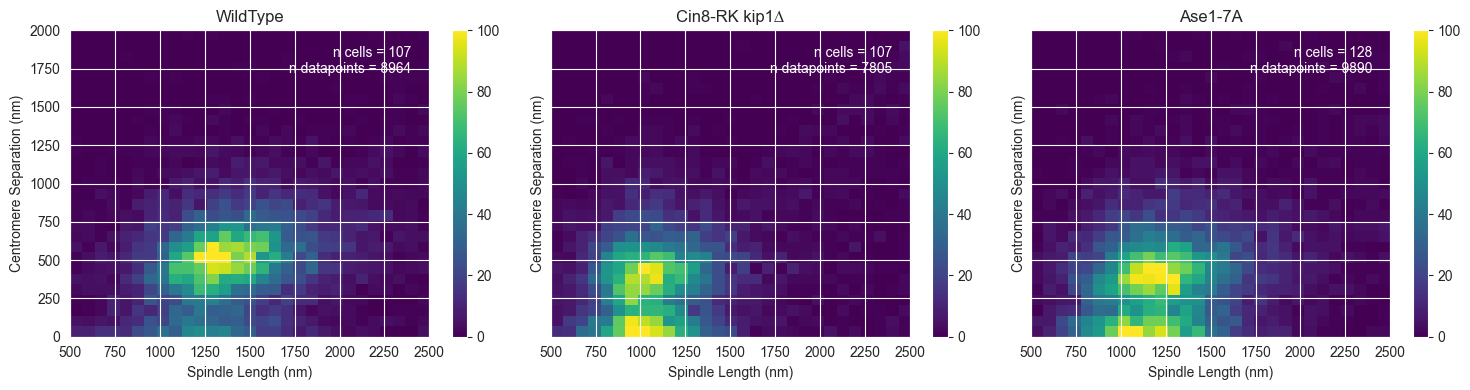

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

def plot_heatmap(ax, data, vmax=100):
    # Plot the histogram using the given data. Use the same bins for all strains. Units should be converted to nm. 
    data = data.dropna(subset=['Spindle Length (um)', 'Centromere Separation (um)'])
    bins = [np.linspace(500, 2500, 30), np.linspace(0, 2000, 30)]
    heatmap, xedges, yedges = np.histogram2d(data['Spindle Length (um)']*1000, data['Centromere Separation (um)']*1000, bins=bins)
    extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
    im = ax.imshow(heatmap.T, extent=extent, origin='lower', aspect='auto', cmap='viridis', vmin=0, vmax=vmax)
    plt.colorbar(im, ax=ax) 
    
    # Add a label in the upper right corner of the heatmap showing the number of cells in the data.
    num_cells = len(data['Cell ID'].unique())
    num_datapoints = len(data)
    ax.text(0.95, 0.95, f'n cells = {num_cells}\nn datapoints = {num_datapoints}', transform=ax.transAxes, ha='right', va='top', fontsize=10, color='white', bbox=dict(facecolor='none', alpha=0.5, edgecolor='none'))
    
    ax.set_xlabel('Spindle Length (nm)')
    ax.set_ylabel('Centromere Separation (nm)')
    
plot_heatmap(axs[0], traj_data[traj_data['Mutant'] == 'WT'])
axs[0].set_title('WildType')

plot_heatmap(axs[1], traj_data[traj_data['Mutant'] == 'Cin8-RK kip1∆'])
axs[1].set_title('Cin8-RK kip1∆')

plot_heatmap(axs[2], traj_data[traj_data['Mutant'] == 'Ase1-7A'])
axs[2].set_title('Ase1-7A')

plt.tight_layout()
saveplot('./figs/spindle_length_vs_centromere_separation_heatmaps.png', dpi=300)

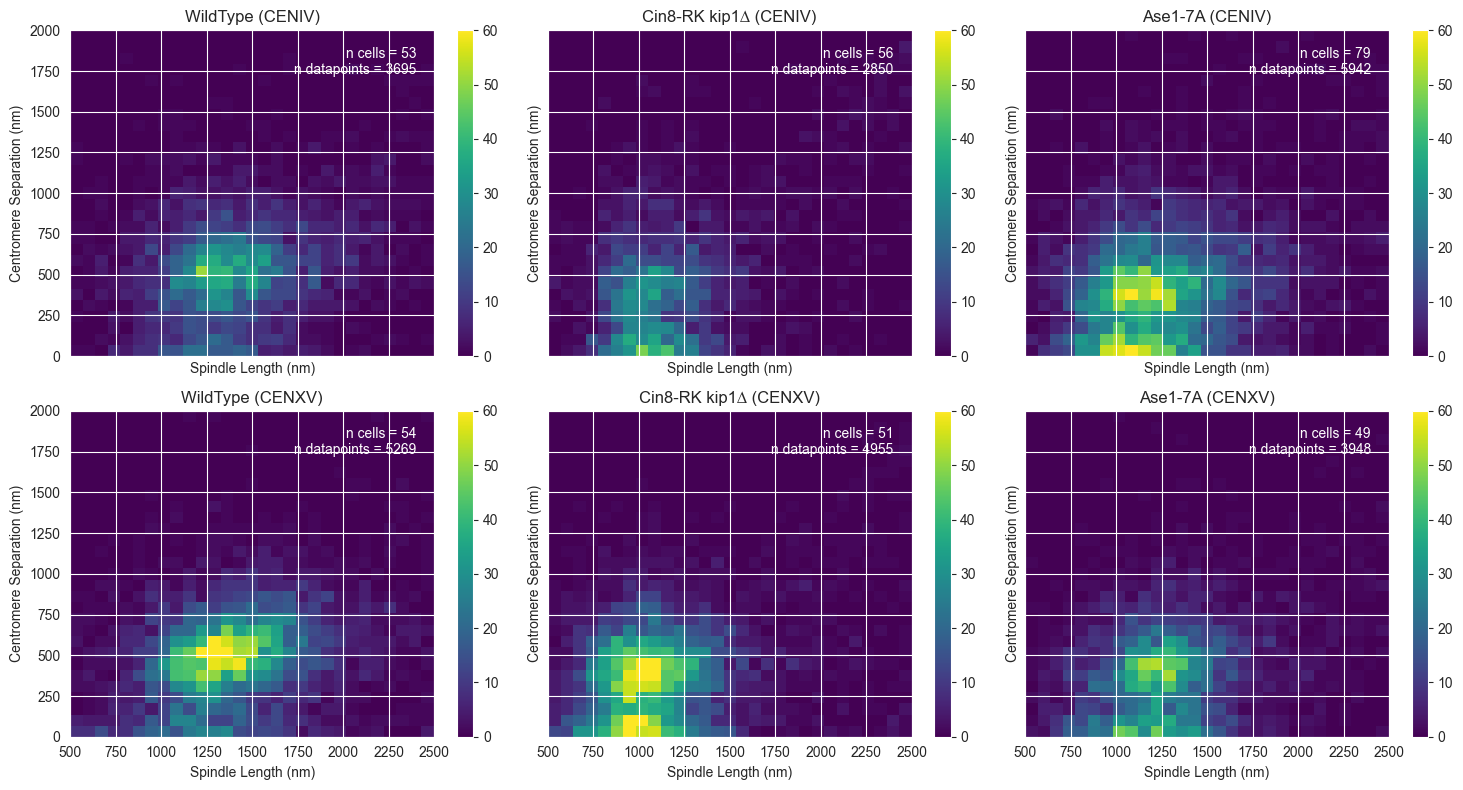

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
vmax = 60

plot_heatmap(axs[0, 0], traj_data[(traj_data['Mutant'] == 'WT') & (traj_data['CEN'] == 'CENIV')], vmax=vmax)
axs[0, 0].set_title('WildType (CENIV)')

plot_heatmap(axs[0, 1], traj_data[(traj_data['Mutant'] == 'Cin8-RK kip1∆') & (traj_data['CEN'] == 'CENIV')], vmax=vmax)
axs[0, 1].set_title('Cin8-RK kip1∆ (CENIV)')

plot_heatmap(axs[0, 2], traj_data[(traj_data['Mutant'] == 'Ase1-7A') & (traj_data['CEN'] == 'CENIV')], vmax=vmax)
axs[0, 2].set_title('Ase1-7A (CENIV)')

plot_heatmap(axs[1, 0], traj_data[(traj_data['Mutant'] == 'WT') & (traj_data['CEN'] == 'CENXV')], vmax=vmax)
axs[1, 0].set_title('WildType (CENXV)')

plot_heatmap(axs[1, 1], traj_data[(traj_data['Mutant'] == 'Cin8-RK kip1∆') & (traj_data['CEN'] == 'CENXV')], vmax=vmax)
axs[1, 1].set_title('Cin8-RK kip1∆ (CENXV)')

plot_heatmap(axs[1, 2], traj_data[(traj_data['Mutant'] == 'Ase1-7A') & (traj_data['CEN'] == 'CENXV')], vmax=vmax)
axs[1, 2].set_title('Ase1-7A (CENXV)')

plt.tight_layout()

# Plot the Tension State Occupancy Over Time

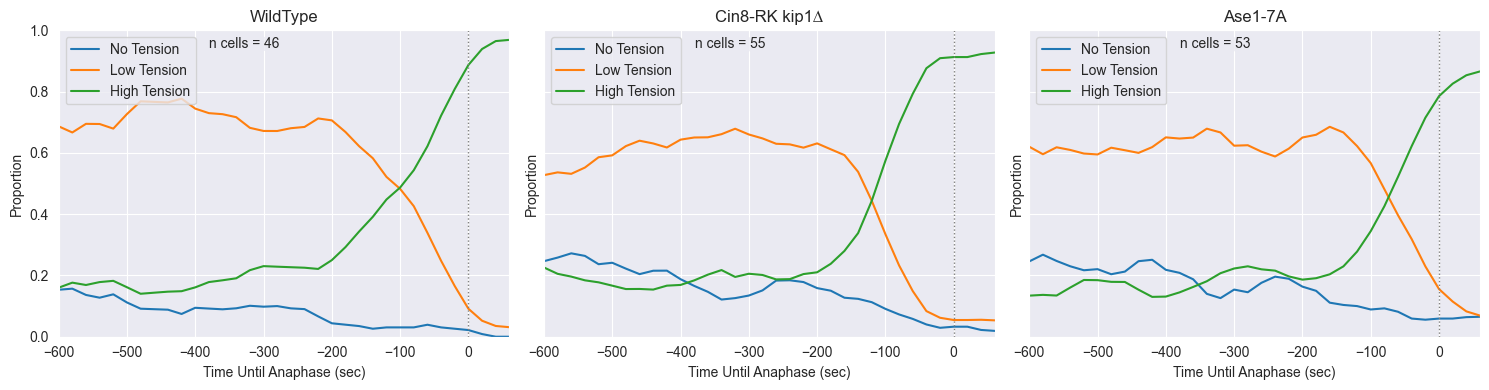

In [11]:
# Cells are aligned on anaphase onset: negative values are before anaphase,
# zero is onset, and positive values are after it.
ANAPHASE_COLUMN = 'Time Until Anaphase (sec)'

# Coverage falls off on both sides of anaphase, so only plot the times where at
# least this many cells contribute to the average.
MIN_CELLS = 5

# Width of the sliding window, in timepoints. Timepoints are TIME_STEP seconds
# apart, so 5 points covers 100 seconds.
WINDOW_SIZE = 5

# Gap between the right edge of the legend and the cell count, in axes units.
LABEL_GAP = 0.03

def plot_state_probabilities(ax, data): 
    """Plot the proportion of the observations in each state as a function of the time until
    anaphase onset."""
    # Only cells with an annotated anaphase can be placed on this axis.
    data = data.dropna(subset=[ANAPHASE_COLUMN, 'Tension Classification'])

    # Count how many cells are in each state at every time relative to anaphase.
    counts = pd.crosstab(data[ANAPHASE_COLUMN], data['Tension Classification'])

    # Drop the times where only a handful of cells are left.
    counts = counts[counts.sum(axis=1) >= MIN_CELLS]

    # Add up the counts over a small sliding window.
    counts = counts.rolling(WINDOW_SIZE, center=True, min_periods=1).sum()

    # Divide each row by its total to get the proportion of the observations in
    # the window that fall into each state.
    proportions = counts.div(counts.sum(axis=1), axis=0)

    for state in et.STATE_LABELS:
        if state not in proportions.columns:
            continue

        ax.plot(proportions.index, proportions[state], label=state)

    # Mark anaphase onset.
    ax.axvline(0, color='gray', linestyle=':', linewidth=1)
    
    # Make the X axis have reasonable bounds. 
    ax.set_xlim(-600, 60)

    ax.set_xlabel('Time Until Anaphase (sec)')
    ax.set_ylabel('Proportion')
    ax.set_ylim(0, 1)

    # Draw the legend first so its size is known before the label is placed.
    legend = ax.legend(loc='upper left')

    # Add a label showing the number of cells that are in the image, sitting
    # just to the right of the legend. A legend only has a size once it has
    # been drawn, and the axes change width when the layout is tidied, so settle
    # the layout and draw before converting the legend's size into axes units.
    ax.figure.tight_layout()
    ax.figure.canvas.draw()
    legend_box = legend.get_window_extent().transformed(ax.transAxes.inverted())

    # Copy the legend's own frame so the two boxes look identical. The colours
    # already carry the legend's alpha, so it must not be applied a second time.
    legend_frame = legend.get_frame()
    label_style = dict(
        facecolor=legend_frame.get_facecolor(),
        edgecolor='none',#legend_frame.get_edgecolor(),
        linewidth=legend_frame.get_linewidth(),
        boxstyle=legend_frame.get_boxstyle(),
    )

    num_cells = len(data['Cell ID'].unique())
    label = ax.text(legend_box.x1 + LABEL_GAP, legend_box.y1, f'n cells = {num_cells}',
                    transform=ax.transAxes, ha='left', va='top',
                    fontsize=legend.get_texts()[0].get_fontsize(), bbox=label_style)

    # The text sits inside its own padded box, so aligning the text does not
    # align the boxes. Measure the drawn box and shift the label until its top
    # edge matches the legend's and its left edge sits one gap to the right.
    ax.figure.canvas.draw()
    label_box = label.get_bbox_patch().get_window_extent().transformed(ax.transAxes.inverted())
    x, y = label.get_position()
    label.set_position((x + (legend_box.x1 + LABEL_GAP - label_box.x0),
                        y + (legend_box.y1 - label_box.y1)))
    
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

plot_state_probabilities(axs[0], traj_data[(traj_data['Mutant'] == 'WT')])
axs[0].set_title('WildType')

plot_state_probabilities(axs[1], traj_data[(traj_data['Mutant'] == 'Cin8-RK kip1∆')])
axs[1].set_title('Cin8-RK kip1∆')

plot_state_probabilities(axs[2], traj_data[(traj_data['Mutant'] == 'Ase1-7A')])
axs[2].set_title('Ase1-7A')

plt.tight_layout()
saveplot('./figs/tension_state_occupancy_over_time.png', dpi=300)

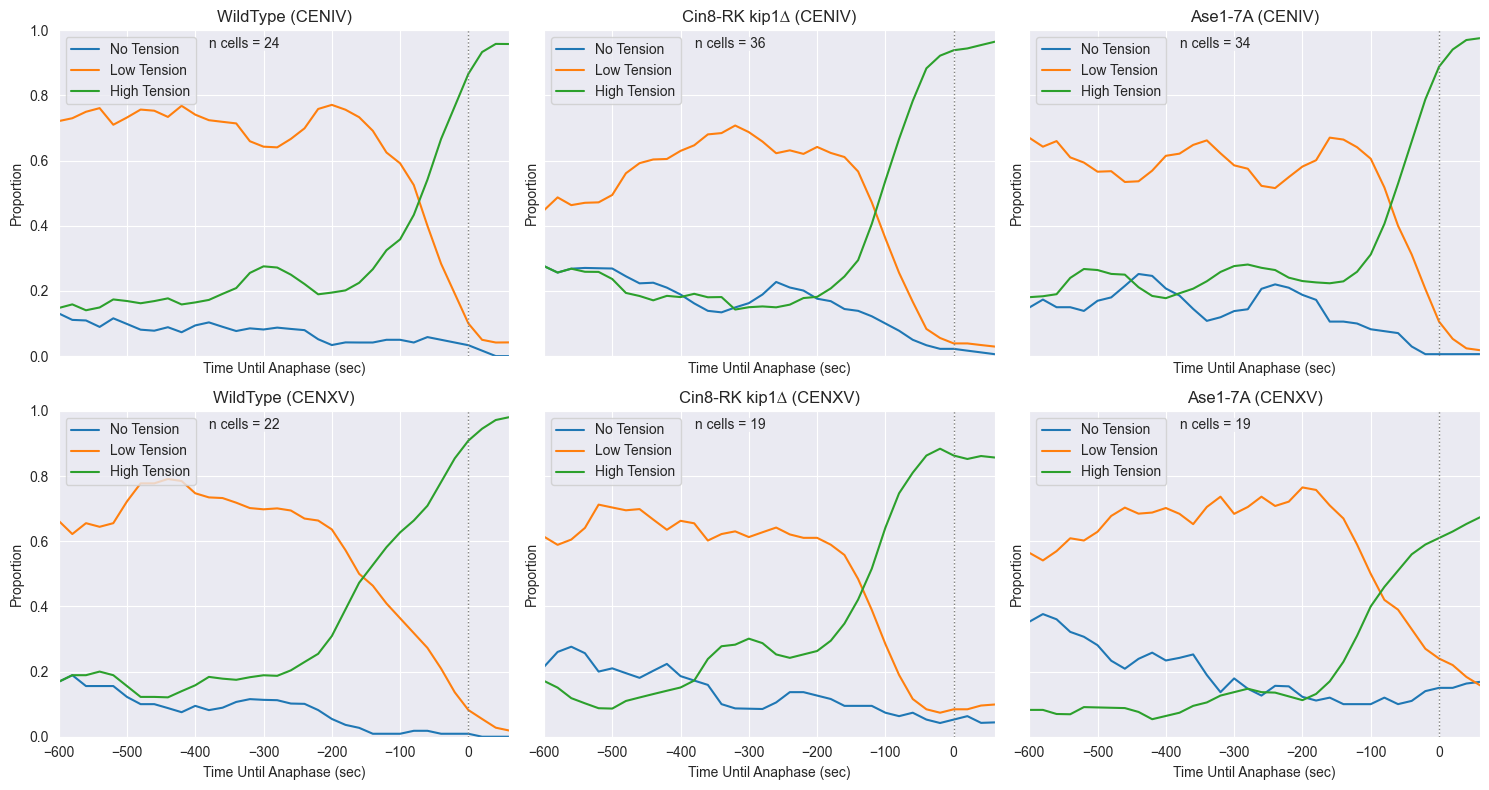

In [12]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)

plot_state_probabilities(axs[0, 0], traj_data[(traj_data['Mutant'] == 'WT') & (traj_data['CEN'] == 'CENIV')])
axs[0, 0].set_title('WildType (CENIV)')

plot_state_probabilities(axs[0, 1], traj_data[(traj_data['Mutant'] == 'Cin8-RK kip1∆') & (traj_data['CEN'] == 'CENIV')])
axs[0, 1].set_title('Cin8-RK kip1∆ (CENIV)')

plot_state_probabilities(axs[0, 2], traj_data[(traj_data['Mutant'] == 'Ase1-7A') & (traj_data['CEN'] == 'CENIV')])
axs[0, 2].set_title('Ase1-7A (CENIV)')

plot_state_probabilities(axs[1, 0], traj_data[(traj_data['Mutant'] == 'WT') & (traj_data['CEN'] == 'CENXV')])
axs[1, 0].set_title('WildType (CENXV)')

plot_state_probabilities(axs[1, 1], traj_data[(traj_data['Mutant'] == 'Cin8-RK kip1∆') & (traj_data['CEN'] == 'CENXV')])
axs[1, 1].set_title('Cin8-RK kip1∆ (CENXV)')

plot_state_probabilities(axs[1, 2], traj_data[(traj_data['Mutant'] == 'Ase1-7A') & (traj_data['CEN'] == 'CENXV')])
axs[1, 2].set_title('Ase1-7A (CENXV)')

plt.tight_layout()
saveplot('./figs/tension_state_occupancy_over_time_by_cen.png', dpi=300)

# Plot the re-attachment time distribution. 

This is just the run length of no-tension states uninterrupted by any other tension states. 

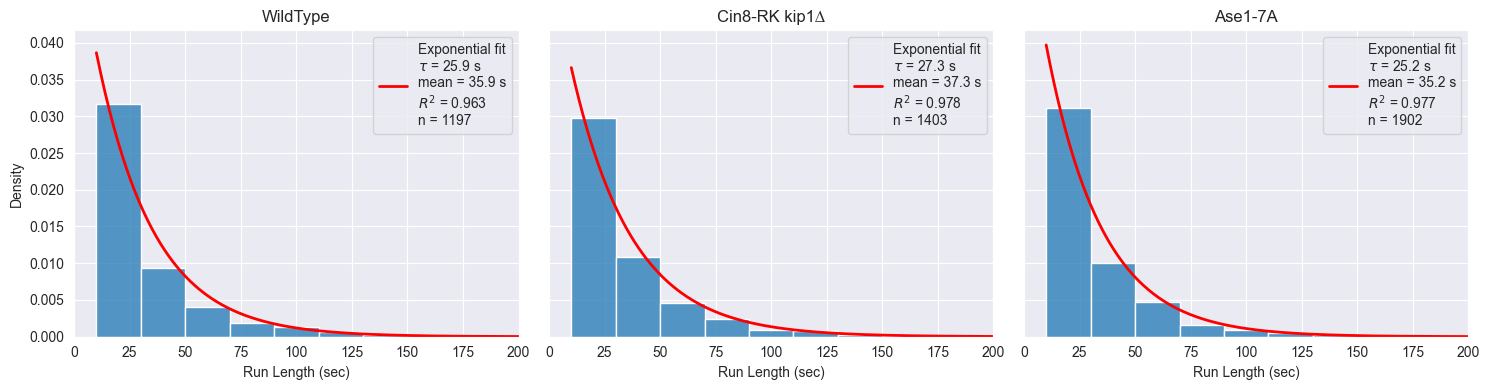

In [13]:
from scipy.stats import expon

# Seconds per timepoint for the main dataset. Passed explicitly to every
# function below so that data recorded at a different rate can be analysed by
# passing its own time step instead.
TIME_STEP_SECONDS = 20.0

# Only used to keep the axis readable. The histogram and the fit always use
# every run, including the few very long ones beyond this limit.
MAX_PLOTTED_RUN_LENGTH = 200.0

def extract_run_lengths(data, state, time_step):
    """Extract the run lengths of a given state from the data, in seconds.

    A run is a stretch of consecutive timepoints in one cell that are all in the
    same state. The length is counted in timepoints and then converted using
    *time_step*, which is the number of seconds between timepoints."""
    run_lengths = []
    for cell_id, cell_data in data.groupby('Cell ID'):
        # Get the indices where the state is present.
        state_indices = cell_data.index[cell_data['Tension Classification'] == state].tolist()
        if not state_indices:
            continue

        # Find the contiguous runs of indices.
        runs = np.split(state_indices, np.where(np.diff(state_indices) != 1)[0] + 1)
        run_lengths.extend([len(run) for run in runs])

    # Convert from a number of timepoints into seconds.
    return np.array(run_lengths) * time_step

def build_run_length_bins(run_lengths, time_step):
    """Build histogram bins that match how run lengths are measured.

    A run length can only be a whole number of timepoints, so the only values
    that ever occur are multiples of *time_step*. Putting one bin around each of
    those values keeps every bin equally populated by construction. Evenly
    spaced bins of any other width leave some bins empty while letting others
    capture two values, which gives the histogram a comb-like look that is an
    artefact of the binning rather than anything in the data."""
    first_edge = time_step / 2
    last_edge = run_lengths.max() + time_step
    return np.arange(first_edge, last_edge, time_step)

def fit_exponential(run_lengths, time_step):
    """Fit an exponential to the run lengths and return its loc and scale.

    The exponential is anchored at the lower edge of the first bin rather than
    at the shortest recorded run. A run seen at a single timepoint really means
    a duration somewhere inside that first bin, so the distribution should start
    where the bin starts. Passing `floc` fixes that offset and leaves only the
    decay constant to be fitted."""
    return expon.fit(run_lengths, floc=time_step / 2)

def compute_fit_r_squared(run_lengths, edges, loc, scale):
    """Compute the R^2 of an exponential fit against the binned run lengths.

    Run lengths are quantised, so the fair comparison is between the height of
    each histogram bin and the probability mass the exponential places in that
    same bin. Using the density at the bin centre instead would misjudge a
    distribution this steep, because the density changes a lot across one bin.

    This one needs no time step: the bin edges already carry it."""
    observed, _ = np.histogram(run_lengths, bins=edges, density=True)

    # Probability mass in each bin, divided by the bin width to put it on the
    # same density scale as the histogram.
    predicted = np.diff(expon.cdf(edges, loc=loc, scale=scale)) / np.diff(edges)

    residual_sum_of_squares = np.sum((observed - predicted) ** 2)
    total_sum_of_squares = np.sum((observed - np.mean(observed)) ** 2)

    return 1.0 - residual_sum_of_squares / total_sum_of_squares

def plot_run_length_distribution(ax, data, state, time_step,
                                 max_run_length=MAX_PLOTTED_RUN_LENGTH):
    """Plot the distribution of run lengths for a given state, with an exponential fit."""
    run_lengths = extract_run_lengths(data, state, time_step)

    edges = build_run_length_bins(run_lengths, time_step)
    sns.histplot(run_lengths, bins=edges, stat='density', ax=ax)

    # Fit the exponential and draw it on top of the histogram.
    loc, scale = fit_exponential(run_lengths, time_step)
    r_squared = compute_fit_r_squared(run_lengths, edges, loc, scale)

    curve = np.linspace(edges[0], edges[-1], 500)
    fit_label = (f'Exponential fit\n'
                 f'$\\tau$ = {scale:.1f} s\n'
                 f'mean = {np.mean(run_lengths):.1f} s\n'
                 f'$R^2$ = {r_squared:.3f}\n'
                 f'n = {len(run_lengths)}')
    ax.plot(curve, expon.pdf(curve, loc=loc, scale=scale),
            color='red', linewidth=2, label=fit_label)

    ax.set_xlim(0, max_run_length)
    ax.set_xlabel('Run Length (sec)')
    ax.set_ylabel('Density')
    ax.set_title(f'Run Length Distribution for {state}')
    ax.legend()

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

plot_run_length_distribution(axs[0], traj_data[traj_data['Mutant'] == 'WT'], 'No Tension', TIME_STEP_SECONDS)
plot_run_length_distribution(axs[1], traj_data[traj_data['Mutant'] == 'Cin8-RK kip1∆'], 'No Tension', TIME_STEP_SECONDS)
plot_run_length_distribution(axs[2], traj_data[traj_data['Mutant'] == 'Ase1-7A'], 'No Tension', TIME_STEP_SECONDS)

axs[0].set_title('WildType')
axs[1].set_title('Cin8-RK kip1∆')
axs[2].set_title('Ase1-7A')

plt.tight_layout()

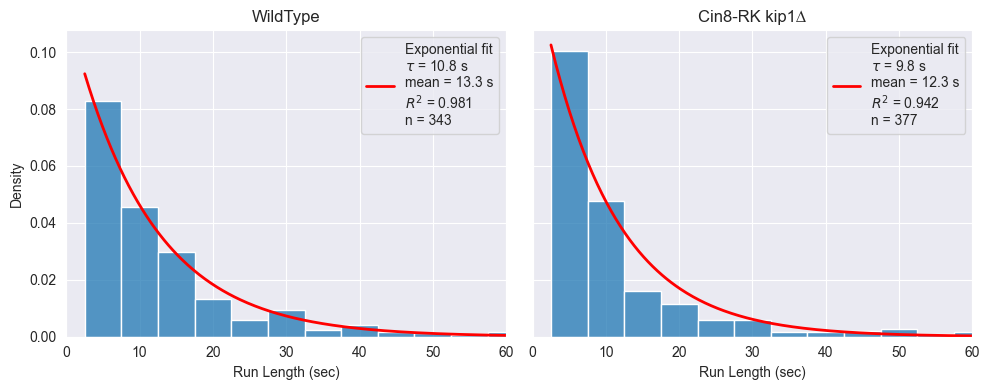

In [14]:
# The high speed data is acquired every 5 seconds rather than every 20, so it
# needs its own time step. Note that the Time (sec) column in this file was
# written out using the 20 second step, but the run lengths are counted from
# consecutive timepoints rather than from that column, so they are unaffected.
HIGH_SPEED_TIME_STEP_SECONDS = 5.0

hs_traj_data = pd.read_csv("high_speed_trajectories/all_trajectories.csv")
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

plot_run_length_distribution(axs[0], hs_traj_data[hs_traj_data['Mutant'] == 'WT'], 'No Tension',
                             HIGH_SPEED_TIME_STEP_SECONDS, max_run_length=60.0)
plot_run_length_distribution(axs[1], hs_traj_data[hs_traj_data['Mutant'] == 'Cin8-RK kip1∆'], 'No Tension',
                             HIGH_SPEED_TIME_STEP_SECONDS, max_run_length=60.0)

axs[0].set_title('WildType')
axs[1].set_title('Cin8-RK kip1∆')

plt.tight_layout()
saveplot('./figs/high_speed_run_length_distributions.png', dpi=300)

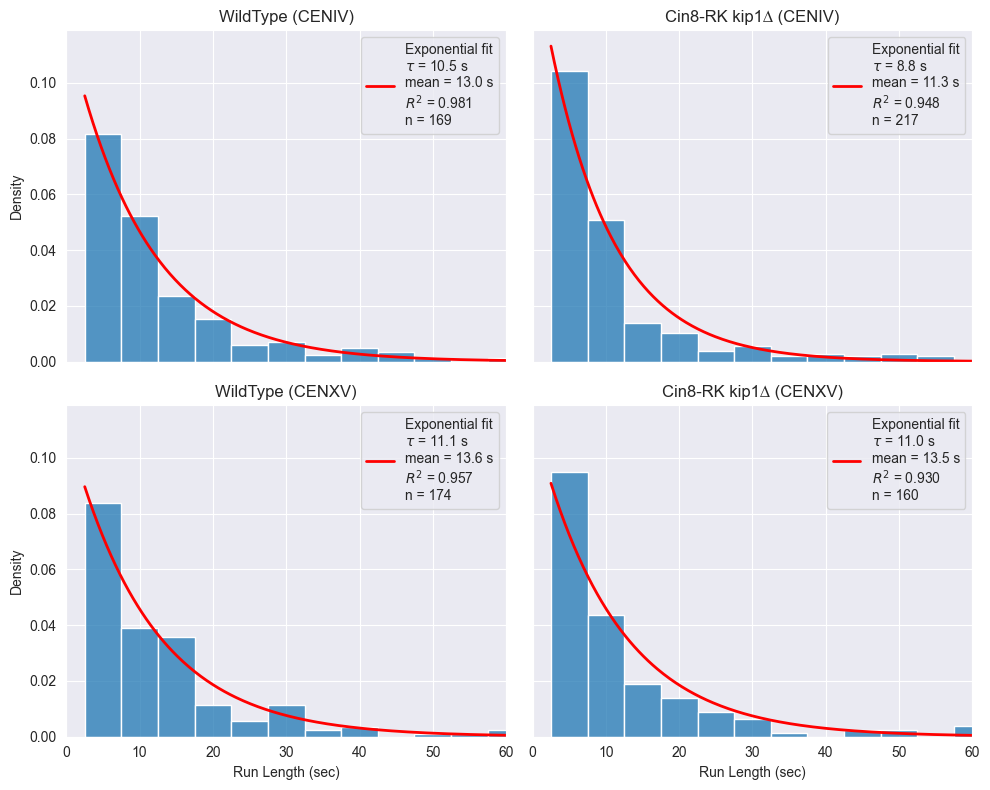

In [21]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

plot_run_length_distribution(axs[0, 0], hs_traj_data[(hs_traj_data['Mutant'] == 'WT') & (hs_traj_data['CEN'] == 'CENIV')], 'No Tension',
                             HIGH_SPEED_TIME_STEP_SECONDS, max_run_length=60.0)
plot_run_length_distribution(axs[0, 1], hs_traj_data[(hs_traj_data['Mutant'] == 'Cin8-RK kip1∆') & (hs_traj_data['CEN'] == 'CENIV')], 'No Tension',
                             HIGH_SPEED_TIME_STEP_SECONDS, max_run_length=60.0)
plot_run_length_distribution(axs[1, 0], hs_traj_data[(hs_traj_data['Mutant'] == 'WT') & (hs_traj_data['CEN'] == 'CENXV')], 'No Tension',
                             HIGH_SPEED_TIME_STEP_SECONDS, max_run_length=60.0)
plot_run_length_distribution(axs[1, 1], hs_traj_data[(hs_traj_data['Mutant'] == 'Cin8-RK kip1∆') & (hs_traj_data['CEN'] == 'CENXV')], 'No Tension',
                             HIGH_SPEED_TIME_STEP_SECONDS, max_run_length=60.0)

axs[0, 0].set_title('WildType (CENIV)')
axs[0, 1].set_title('Cin8-RK kip1∆ (CENIV)')
axs[1, 0].set_title('WildType (CENXV)')
axs[1, 1].set_title('Cin8-RK kip1∆ (CENXV)')

plt.tight_layout()
saveplot('./figs/high_speed_run_length_distributions.png', dpi=300)


# Compare the re-attachment times of the two high speed strains.

Likelihood ratio test of whether the two exponential distributions share a single mean.

In [15]:
from scipy.stats import chi2

def exponential_log_likelihood(run_lengths, loc, scale):
    """Log likelihood of a shifted exponential with the given scale."""
    offset = run_lengths - loc
    return -len(offset) * np.log(scale) - np.sum(offset) / scale

def likelihood_ratio_test(run_lengths_a, run_lengths_b, time_step):
    """Test whether two sets of run lengths share a single exponential mean.

    The null hypothesis is that both samples come from one exponential; the
    alternative gives each sample its own. Both are shifted by the same amount,
    so the only parameter that differs between them is the scale, which for an
    exponential is the mean of the shifted data.

    The alternative has exactly one extra free parameter, so twice the gain in
    log likelihood is compared against a chi-squared distribution with one
    degree of freedom."""
    loc = time_step / 2
    offset_a = run_lengths_a - loc
    offset_b = run_lengths_b - loc

    # The maximum likelihood scale of an exponential is the mean of the data.
    scale_a = np.mean(offset_a)
    scale_b = np.mean(offset_b)
    scale_shared = np.mean(np.concatenate([offset_a, offset_b]))

    log_likelihood_separate = (exponential_log_likelihood(run_lengths_a, loc, scale_a)
                               + exponential_log_likelihood(run_lengths_b, loc, scale_b))
    log_likelihood_shared = (exponential_log_likelihood(run_lengths_a, loc, scale_shared)
                             + exponential_log_likelihood(run_lengths_b, loc, scale_shared))

    statistic = 2 * (log_likelihood_separate - log_likelihood_shared)
    p_value = chi2.sf(statistic, df=1)

    return statistic, p_value, scale_a, scale_b, scale_shared

wt_runs = extract_run_lengths(hs_traj_data[hs_traj_data['Mutant'] == 'WT'],
                              'No Tension', HIGH_SPEED_TIME_STEP_SECONDS)
cin8_runs = extract_run_lengths(hs_traj_data[hs_traj_data['Mutant'] == 'Cin8-RK kip1∆'],
                                'No Tension', HIGH_SPEED_TIME_STEP_SECONDS)

statistic, p_value, scale_wt, scale_cin8, scale_shared = likelihood_ratio_test(
    wt_runs, cin8_runs, HIGH_SPEED_TIME_STEP_SECONDS)

print(f"WT       n = {len(wt_runs):4d}   tau = {scale_wt:6.2f} s   mean run = {np.mean(wt_runs):6.2f} s")
print(f"Cin8-RK  n = {len(cin8_runs):4d}   tau = {scale_cin8:6.2f} s   mean run = {np.mean(cin8_runs):6.2f} s")
print(f"shared                tau = {scale_shared:6.2f} s")
print()
print(f"likelihood ratio statistic = {statistic:.4f}   df = 1   p = {p_value:.4g}")

WT       n =  343   tau =  10.82 s   mean run =  13.32 s
Cin8-RK  n =  377   tau =   9.75 s   mean run =  12.25 s
shared                tau =  10.26 s

likelihood ratio statistic = 1.9444   df = 1   p = 0.1632


# Check the comparison against censoring and against the discrete model.

Runs clipped by the edges of a trajectory are handled explicitly, and the continuous exponential is replaced by the geometric distribution over whole timepoints.

In [16]:
# Two refinements to the test above: account for runs that were cut off by the
# edges of a trajectory, and swap the continuous exponential for the discrete
# distribution that actually describes whole numbers of timepoints.

def extract_runs_with_censoring(data, state):
    """Extract run lengths in timepoints, flagging the runs that were cut off.

    A run touching the first classified timepoint of a cell started before
    recording began, so its true length is unknown: it is left censored. A run
    touching the last classified timepoint was still going when recording
    stopped, so its length is only known to be at least what was seen: it is
    right censored. Ignoring either biases the mean downwards, because the long
    runs are the ones most likely to be clipped."""
    lengths = []
    left_censored = []
    right_censored = []

    for cell_id, cell_data in data.groupby('Cell ID'):
        # The trajectory edges are the first and last timepoints that actually
        # carry a classification.
        classified = cell_data.index[cell_data['Tension Classification'].notna()]
        if len(classified) == 0:
            continue
        first_index = classified.min()
        last_index = classified.max()

        state_indices = cell_data.index[cell_data['Tension Classification'] == state].tolist()
        if not state_indices:
            continue

        runs = np.split(state_indices, np.where(np.diff(state_indices) != 1)[0] + 1)
        for run in runs:
            lengths.append(len(run))
            left_censored.append(run[0] == first_index)
            right_censored.append(run[-1] == last_index)

    return np.array(lengths), np.array(left_censored), np.array(right_censored)

def censored_exponential_mle(run_lengths, is_censored, time_step):
    """Maximum likelihood scale of a shifted exponential with right censoring.

    A censored run still contributes the time it was observed for, but it does
    not count as a finished run, so the estimate is the total observed time
    divided by the number of runs that were seen to finish."""
    offset = run_lengths - time_step / 2
    return np.sum(offset) / np.sum(~is_censored)

def censored_exponential_log_likelihood(run_lengths, is_censored, time_step, scale):
    """Log likelihood of a shifted exponential when some runs are right censored.

    A finished run contributes its density. A censored run only tells us its
    duration exceeded what was seen, so it contributes its survival function,
    which for an exponential simply drops the leading log(scale) term."""
    offset = run_lengths - time_step / 2
    number_finished = np.sum(~is_censored)
    return -number_finished * np.log(scale) - np.sum(offset) / scale

def censored_exponential_lrt(runs_a, censored_a, runs_b, censored_b, time_step):
    """Likelihood ratio test on two exponential means, allowing right censoring."""
    scale_a = censored_exponential_mle(runs_a, censored_a, time_step)
    scale_b = censored_exponential_mle(runs_b, censored_b, time_step)

    # Under the null the two share one scale, so pool both the observed time and
    # the number of finished runs.
    total_offset = np.sum(runs_a - time_step / 2) + np.sum(runs_b - time_step / 2)
    total_finished = np.sum(~censored_a) + np.sum(~censored_b)
    scale_shared = total_offset / total_finished

    separate = (censored_exponential_log_likelihood(runs_a, censored_a, time_step, scale_a)
                + censored_exponential_log_likelihood(runs_b, censored_b, time_step, scale_b))
    shared = (censored_exponential_log_likelihood(runs_a, censored_a, time_step, scale_shared)
              + censored_exponential_log_likelihood(runs_b, censored_b, time_step, scale_shared))

    statistic = 2 * (separate - shared)
    return statistic, chi2.sf(statistic, df=1), scale_a, scale_b

def geometric_log_likelihood(counts, escape_probability):
    """Log likelihood of a geometric distribution over whole timepoint counts.

    This is the discrete counterpart of the exponential. A run of n timepoints
    means n-1 opportunities to leave the state were not taken and the nth was,
    so P(n) = (1-p)^(n-1) * p. It is the honest model when runs are only a few
    timepoints long and calling them a continuous duration is a stretch."""
    return (np.sum(counts - 1) * np.log(1 - escape_probability)
            + len(counts) * np.log(escape_probability))

def geometric_lrt(counts_a, counts_b):
    """Likelihood ratio test on two geometric means, in whole timepoints."""
    # The maximum likelihood escape probability is one over the mean run length.
    probability_a = 1 / np.mean(counts_a)
    probability_b = 1 / np.mean(counts_b)
    probability_shared = 1 / np.mean(np.concatenate([counts_a, counts_b]))

    separate = (geometric_log_likelihood(counts_a, probability_a)
                + geometric_log_likelihood(counts_b, probability_b))
    shared = (geometric_log_likelihood(counts_a, probability_shared)
              + geometric_log_likelihood(counts_b, probability_shared))

    statistic = 2 * (separate - shared)
    return statistic, chi2.sf(statistic, df=1), 1 / probability_a, 1 / probability_b

step = HIGH_SPEED_TIME_STEP_SECONDS

wt_runs, wt_left, wt_right = extract_runs_with_censoring(
    hs_traj_data[hs_traj_data['Mutant'] == 'WT'], 'No Tension')
cin8_runs, cin8_left, cin8_right = extract_runs_with_censoring(
    hs_traj_data[hs_traj_data['Mutant'] == 'Cin8-RK kip1∆'], 'No Tension')

print('How many runs were cut off by the edges of a trajectory:')
for name, left, right in [('WT', wt_left, wt_right), ('Cin8-RK kip1∆', cin8_left, cin8_right)]:
    complete = ~(left | right)
    print(f'  {name:16s} {len(left):4d} runs   left {left.sum():3d}   right {right.sum():3d}'
          f'   complete {complete.sum():3d} ({complete.mean():.1%})')

# Exponential test: drop the left censored runs, since their start is unknown,
# and keep the right censored ones as censored observations.
wt_keep = ~wt_left
cin8_keep = ~cin8_left
statistic, p_value, tau_wt, tau_cin8 = censored_exponential_lrt(
    wt_runs[wt_keep] * step, wt_right[wt_keep],
    cin8_runs[cin8_keep] * step, cin8_right[cin8_keep], step)
print(f'\nExponential, right censoring handled:')
print(f'  tau   WT = {tau_wt:5.2f} s    Cin8-RK = {tau_cin8:5.2f} s')
print(f'  LR statistic = {statistic:.4f}   df = 1   p = {p_value:.4g}')

# Geometric test, on the runs that were seen from start to finish.
wt_complete = wt_runs[~(wt_left | wt_right)]
cin8_complete = cin8_runs[~(cin8_left | cin8_right)]
statistic, p_value, mean_wt, mean_cin8 = geometric_lrt(wt_complete, cin8_complete)
print(f'\nGeometric on whole timepoints, complete runs only:')
print(f'  mean  WT = {mean_wt * step:5.2f} s    Cin8-RK = {mean_cin8 * step:5.2f} s')
print(f'  LR statistic = {statistic:.4f}   df = 1   p = {p_value:.4g}')

# Geometric on every run, so the effect of dropping the censored ones is visible.
statistic, p_value, mean_wt, mean_cin8 = geometric_lrt(wt_runs, cin8_runs)
print(f'\nGeometric on whole timepoints, every run:')
print(f'  mean  WT = {mean_wt * step:5.2f} s    Cin8-RK = {mean_cin8 * step:5.2f} s')
print(f'  LR statistic = {statistic:.4f}   df = 1   p = {p_value:.4g}')

How many runs were cut off by the edges of a trajectory:
  WT                343 runs   left  18   right  10   complete 315 (91.8%)
  Cin8-RK kip1∆     377 runs   left  20   right  11   complete 346 (91.8%)

Exponential, right censoring handled:
  tau   WT = 11.10 s    Cin8-RK =  9.70 s
  LR statistic = 2.9966   df = 1   p = 0.08344

Geometric on whole timepoints, complete runs only:
  mean  WT = 13.05 s    Cin8-RK = 11.92 s
  LR statistic = 2.2442   df = 1   p = 0.1341

Geometric on whole timepoints, every run:
  mean  WT = 13.32 s    Cin8-RK = 12.25 s
  LR statistic = 2.0670   df = 1   p = 0.1505
